# Лабораторна робота № 10
## Математична морфологія бінарних та напівтонових зображень

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, OpenCV (`cv2`), SciPy, Matplotlib

## 1. Мета роботи

Вивчити базові операції математичної морфології (ерозія, діляція, відкриття, закриття), їх похідні (морфологічний градієнт, Top-Hat, Black-Hat) та вплив форми й розміру структуруючого елемента. Застосувати їх до задачі дефектоскопії доріжок друкованої плати: очистити бінарний кадр від шуму та виявити розриви доріжок за відгуком Black-Hat.

## 2. Основні співвідношення

Нехай $A$ — зображення, $B$ — структуруючий елемент (СЕ), $B_z$ — елемент, зсунутий у точку $z$.

- Ерозія: $A \ominus B = \{z : B_z \subseteq A\}$ — зменшує об'єкти, прибирає виступи й дрібні плями ($S$ зменшується).
- Діляція: $A \oplus B = \{z : \hat{B}_z \cap A \neq \varnothing\}$ — збільшує об'єкти, заповнює вузькі розриви й пори.
- Відкриття: $A \circ B = (A \ominus B) \oplus B$ — прибирає світлі об'єкти, менші за СЕ, не змінюючи великих.
- Закриття: $A \bullet B = (A \oplus B) \ominus B$ — заповнює темні розриви й пори, вужчі за СЕ.
- Відкриття й закриття ідемпотентні: $(A \circ B) \circ B = A \circ B$, $(A \bullet B) \bullet B = A \bullet B$.
- Морфологічний градієнт: $G = (A \oplus B) - (A \ominus B)$ — контур об'єкта; дорівнює сумі зовнішнього $(A \oplus B) - A$ та внутрішнього $A - (A \ominus B)$ контурів.
- Top-Hat: $T = A - (A \circ B)$ — яскраві деталі, менші за СЕ. Black-Hat: $K = (A \bullet B) - A$ — темні деталі (розриви, пори), вужчі за СЕ.
- Умова виявлення: елемент $5 \times 5$ заповнює темний розрив шириною $w \le 4$ пікселі; розрив ширше за СЕ закриття не зачіпає, тому Black-Hat його не бачить.

## 3. Індивідуальне завдання (варіант 2)

| Параметр | Значення |
|---|---|
| Структуруючий елемент | прямокутний $5 \times 5$ (`MORPH_RECT`) |
| Кількість ітерацій | 1 |
| Ширина доріжки | 12 пікс. |
| Пороги бінаризації Black-Hat / Top-Hat | 40 / 40 |
| Конвеєр дефектоскопії | Closing $\rightarrow$ Black-Hat |

Джерело даних. У завданні немає знімка плати, тому я згенерував кадр $600 \times 400$ пікселів: чотири горизонтальні доріжки з контактними площадками, вертикальний з'єднувач, вісім розривів шириною 2, 7, 3, 5, 4, 9, 4, 3 пікселі, шум «сіль» (120 цяток на тлі) та «перець» (60 пор усередині доріжок). Для напівтонового варіанта додано нерівномірне освітлення, шум і пилові крапки. Ідеальна маска топології відома, тому якість очищення можна виміряти.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab10_morphology.py`. Графіки зберігаються в каталог `figures/`, тестові зображення — у `data/`.

### Блок 1. Підготовка середовища, імпорт та генерація тестових зображень

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# каталоги для графіків і даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

# параметри варіанта 2
K_SIZE = 5                      # розмір структуруючого елемента (СЕ) 5x5
N_ITER = 1                      # кількість ітерацій
TW = 12                         # ширина доріжки, пікс.
TH_BLACKHAT, TH_TOPHAT = 40, 40  # пороги бінаризації відгуків Black-Hat та Top-Hat

# розриви доріжок: (x центра, y осі доріжки, ширина розриву, пікс.)
BREAKS = [(130, 70, 2), (420, 70, 7), (200, 150, 3), (480, 150, 5),
          (110, 230, 4), (400, 230, 9), (220, 310, 4), (450, 310, 3)]


def generate_morphology_test_scenes(height=400, width=600):
    """
    Бінарна та напівтонова сцени з доріжками друкованої плати.
    Повертає ідеальну маску топології, бінарний кадр із шумом
    (сіль: 120 цяток на тлі, перець: 60 пор усередині доріжок)
    та напівтоновий кадр з нерівномірним освітленням.
    """
    layout = np.zeros((height, width), dtype=np.uint8)
    for y in (70, 150, 230, 310):                               # горизонтальні доріжки
        cv2.rectangle(layout, (40, y - TW // 2), (560, y + TW // 2 - 1), 255, -1)
        cv2.circle(layout, (40, y), 18, 255, -1)                # контактні площадки
        cv2.circle(layout, (560, y), 18, 255, -1)
    cv2.rectangle(layout, (294, 70 - TW // 2), (294 + TW - 1, 310 + TW // 2 - 1), 255, -1)  # з'єднувач

    breaks_zone = np.zeros_like(layout)
    for bx, by, w in BREAKS:                                    # прорізаємо розриви
        x0 = bx - w // 2
        layout[by - TW // 2 - 1:by + TW // 2 + 1, x0:x0 + w] = 0
        breaks_zone[by - TW // 2 - 8:by + TW // 2 + 8, x0 - 8:x0 + w + 8] = 255

    rng = np.random.default_rng(42)
    raw = layout.copy()
    # шум "сіль": окремі яскраві цятки на тлі
    bg = np.argwhere((cv2.dilate(layout, np.ones((5, 5), np.uint8)) == 0))
    for y, x in bg[rng.choice(len(bg), 120, replace=False)]:
        raw[y, x] = 255
    # шум "перець": пори 2x2 усередині доріжок, подалі від розривів
    interior = cv2.erode(layout, np.ones((7, 7), np.uint8))
    interior[breaks_zone > 0] = 0
    inner = np.argwhere(interior > 0)
    for y, x in inner[rng.choice(len(inner), 60, replace=False)]:
        raw[y:y + 2, x:x + 2] = 0

    # напівтоновий кадр: мідь яскрава, підкладка темна, параболічне освітлення,
    # кілька яскравих крапинок пилу, розмиття та шум
    gray = np.where(layout > 0, 200.0, 50.0).astype(np.float32)
    far = np.argwhere(cv2.erode(255 - layout, np.ones((11, 11), np.uint8)) > 0)
    for y, x in far[rng.choice(len(far), 14, replace=False)]:
        gray[y - 1:y + 2, x - 1:x + 2] = 255
    yy, xx = np.mgrid[0:height, 0:width]
    illum = 1.0 - 0.4 * (0.5 * ((xx - width / 2) / (width / 2)) ** 2 + 0.5 * ((yy - height / 2) / (height / 2)) ** 2)
    gray = cv2.GaussianBlur(gray, (0, 0), 1.0) * illum + rng.normal(0, 4, gray.shape)
    return layout, raw, np.clip(gray, 0, 255).astype(np.uint8)


layout, img_raw, img_gray = generate_morphology_test_scenes()
cv2.imwrite("data/binary_tracks_raw.png", img_raw)
cv2.imwrite("data/grayscale_pcb_uneven.png", img_gray)
print("Тестові зображення збережено: data/binary_tracks_raw.png, data/grayscale_pcb_uneven.png")
print(f"Розмір кадру: {img_raw.shape[1]}x{img_raw.shape[0]}, розривів у топології: {len(BREAKS)}, "
      f"ширини розривів: {[b[2] for b in BREAKS]} пікс.")

Тестові зображення збережено: data/binary_tracks_raw.png, data/grayscale_pcb_uneven.png
Розмір кадру: 600x400, розривів у топології: 8, ширини розривів: [2, 7, 3, 5, 4, 9, 4, 3] пікс.


**Тестові сцени:** `data/binary_tracks_raw.png` (бінарний кадр із шумом) та `data/grayscale_pcb_uneven.png` (півтоновий кадр). Розмір кадру $600 \times 400$, розривів 8, ширини розривів 2, 7, 3, 5, 4, 9, 4, 3 пікселі. Три розриви (7, 5 та 9 пікселів) ширші за елемент $5 \times 5$ — вони потрібні, щоб побачити межу застосовності методу.

### Блок 2. Структуруючі елементи


--- СТРУКТУРУЮЧІ ЕЛЕМЕНТИ 5x5 ---
MORPH_RECT (елемент варіанта 2): одиниць 25 з 25
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
MORPH_CROSS: одиниць 9 з 25
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
MORPH_ELLIPSE: одиниць 17 з 25
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


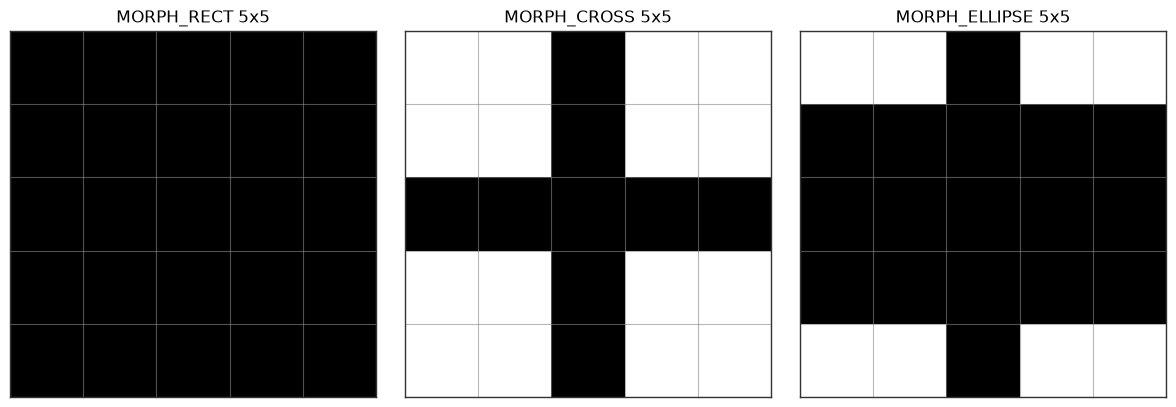

In [2]:
se_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (K_SIZE, K_SIZE))
se_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (K_SIZE, K_SIZE))
se_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_SIZE, K_SIZE))

print("\n--- СТРУКТУРУЮЧІ ЕЛЕМЕНТИ {}x{} ---".format(K_SIZE, K_SIZE))
for name, se in [("MORPH_RECT (елемент варіанта 2)", se_rect), ("MORPH_CROSS", se_cross),
                 ("MORPH_ELLIPSE", se_ellipse)]:
    print(f"{name}: одиниць {int(se.sum())} з {se.size}")
    print(se)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, se, title in [(axes[0], se_rect, "MORPH_RECT 5x5"), (axes[1], se_cross, "MORPH_CROSS 5x5"),
                      (axes[2], se_ellipse, "MORPH_ELLIPSE 5x5")]:
    ax.imshow(se, cmap='gray_r', vmin=0, vmax=1)
    ax.set_xticks(np.arange(-0.5, K_SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, K_SIZE, 1), minor=True)
    ax.grid(which='minor', color='#888888', linewidth=0.8, linestyle='-')
    ax.tick_params(which='both', length=0, labelbottom=False, labelleft=False)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/structuring_elements.png", dpi=300)
plt.show()

**Структуруючі елементи $5 \times 5$** (на рисунку чорним позначено одиниці СЕ):

| Елемент | Одиниць із 25 |
|---|---|
| `MORPH_RECT` (варіант 2) | 25 |
| `MORPH_CROSS` | 9 |
| `MORPH_ELLIPSE` | 17 |

Прямокутник охоплює найбільшу околицю й діє однаково в усіх напрямках по осях та діагоналях; хрест діє лише вздовж осей; еліпс «скруглює» кути, тому він ближчий до круглого.

### Блок 3. Ерозія та діляція


--- ЕРОЗІЯ ТА ДІЛЯЦІЯ (RECT 5x5, 1 ітер.) ---
Початкова площа: 33239 пікс.
Після ерозії: 20950 пікс. (-37.0 %)
Після діляції: 47192 пікс. (+42.0 %)
Розриви після діляції (закритий = розрив ширше за СЕ не зникає):
  x = 130, y =  70, ширина 2 пікс.: закритий
  x = 420, y =  70, ширина 7 пікс.: залишився відкритим
  x = 200, y = 150, ширина 3 пікс.: закритий
  x = 480, y = 150, ширина 5 пікс.: залишився відкритим
  x = 110, y = 230, ширина 4 пікс.: закритий
  x = 400, y = 230, ширина 9 пікс.: залишився відкритим
  x = 220, y = 310, ширина 4 пікс.: закритий
  x = 450, y = 310, ширина 3 пікс.: закритий


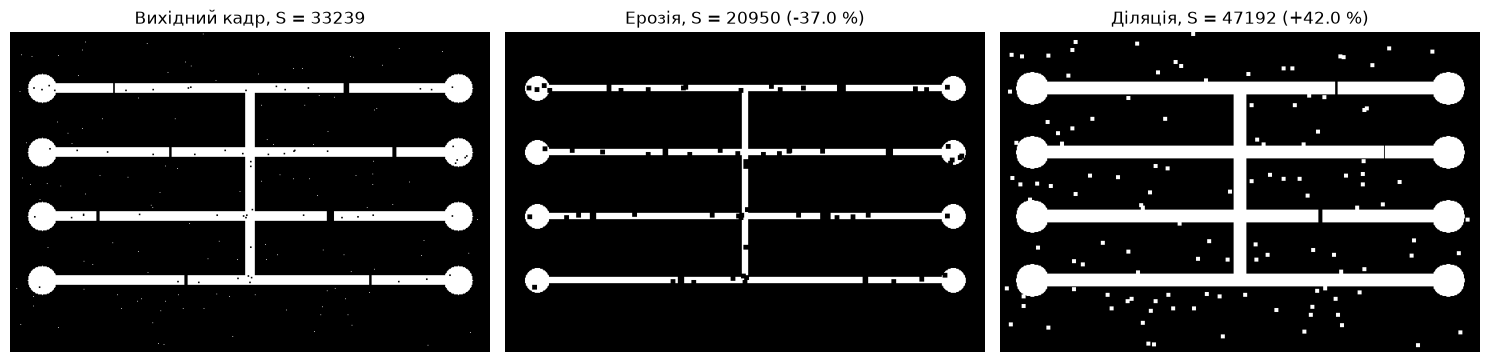

In [3]:
img_eroded = cv2.erode(img_raw, se_rect, iterations=N_ITER)
img_dilated = cv2.dilate(img_raw, se_rect, iterations=N_ITER)

area_raw = cv2.countNonZero(img_raw)
area_er = cv2.countNonZero(img_eroded)
area_dil = cv2.countNonZero(img_dilated)


def break_closed(mask, bx, by, w):
    """Розрив 'закритий', якщо вздовж осі доріжки на ділянці розриву всі пікселі ненульові."""
    x0 = bx - w // 2
    return bool(mask[by, x0:x0 + w].all())


print("\n--- ЕРОЗІЯ ТА ДІЛЯЦІЯ (RECT {0}x{0}, {1} ітер.) ---".format(K_SIZE, N_ITER))
print(f"Початкова площа: {area_raw} пікс.")
print(f"Після ерозії: {area_er} пікс. ({100 * (area_er - area_raw) / area_raw:+.1f} %)")
print(f"Після діляції: {area_dil} пікс. ({100 * (area_dil - area_raw) / area_raw:+.1f} %)")
print("Розриви після діляції (закритий = розрив ширше за СЕ не зникає):")
for bx, by, w in BREAKS:
    print(f"  x = {bx:3d}, y = {by:3d}, ширина {w} пікс.: "
          f"{'закритий' if break_closed(img_dilated, bx, by, w) else 'залишився відкритим'}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, a, title in [(axes[0], img_raw, f"Вихідний кадр, S = {area_raw}"),
                     (axes[1], img_eroded, f"Ерозія, S = {area_er} ({100 * (area_er - area_raw) / area_raw:+.1f} %)"),
                     (axes[2], img_dilated, f"Діляція, S = {area_dil} ({100 * (area_dil - area_raw) / area_raw:+.1f} %)")]:
    ax.imshow(a, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/erosion_dilation_comp.png", dpi=300)
plt.show()

**Ерозія та діляція** (`MORPH_RECT` $5 \times 5$, 1 ітерація):

| Величина | Значення |
|---|---|
| Початкова площа $S$ | 33239 пікс. |
| Після ерозії | 20950 пікс. ($-37.0\ \%$) |
| Після діляції | 47192 пікс. ($+42.0\ \%$) |

Розриви після діляції: закрилися розриви шириною 2, 3, 4, 4, 3 пікселі; залишилися відкритими розриви шириною 7, 5, 9 пікселів. Діляція з елементом $5 \times 5$ нарощує кожну сторону на 2 пікселі, тому закриває розриви до 4 пікселів. Ерозія зменшує площу на 37 % і розширює пори всередині доріжок (див. чорні квадрати на графіку), а діляція роздуває кожну цятку шуму на тлі до квадрата $5 \times 5$. Окремо ні ерозія, ні діляція не очищують кадр — для цього потрібні їх комбінації.

### Блок 4. Відкриття, закриття та зв'язні компоненти


--- ВІДКРИТТЯ ТА ЗАКРИТТЯ ---
Зв'язних компонент: вихідний кадр 129 (з них площею >= 100 пікс.: 9), після відкриття 9, після закриття 112, після закриття та відкриття 4
Хибних пікселів відносно ідеальної топології: вихідний 357, відкриття 523, закриття 359, повне очищення 218
Ідемпотентність: open(open(A)) == open(A): True, close(close(A)) == close(A): True
Розривів, прихованих очищенням (закриття заповнює їх): 5 з 8


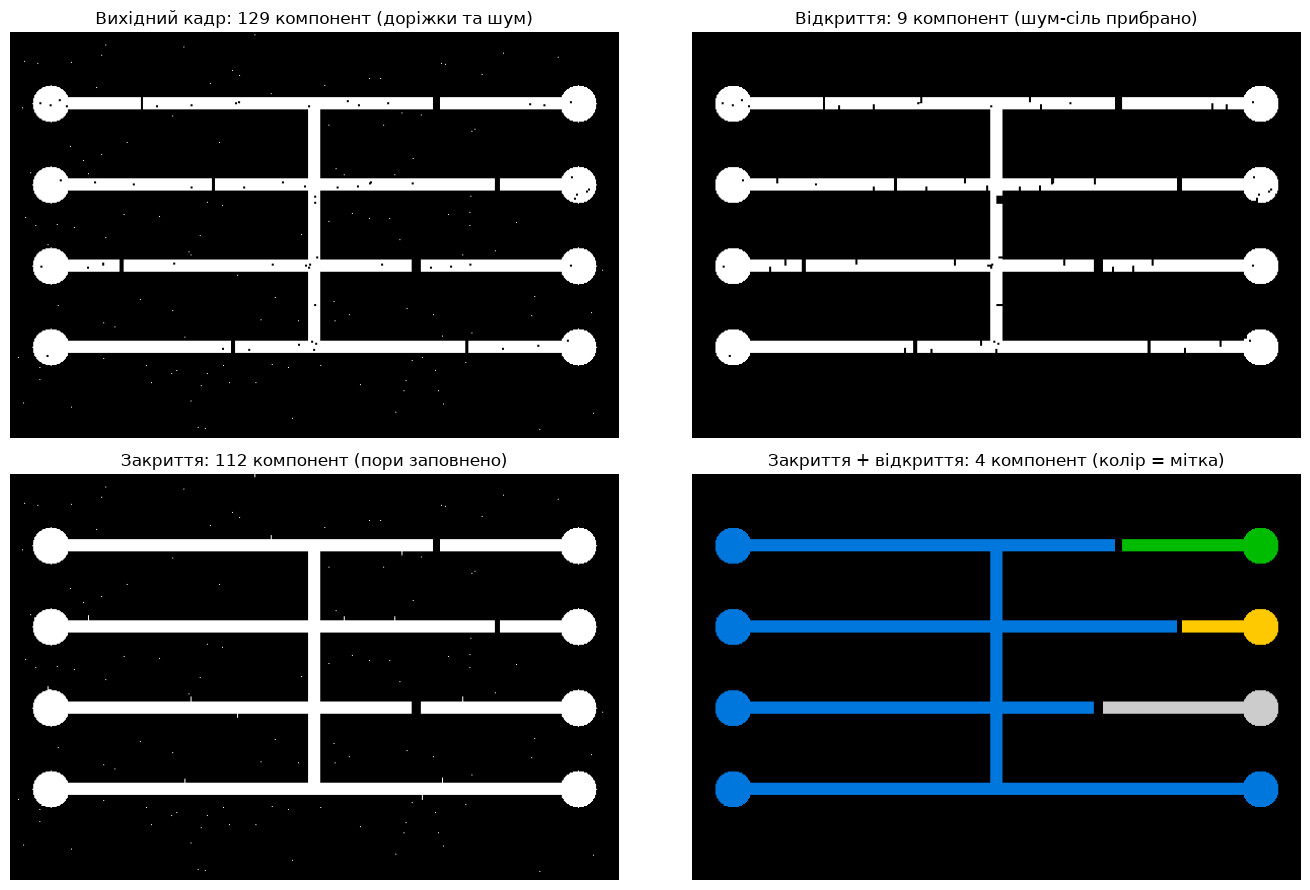

In [4]:
img_opened = cv2.morphologyEx(img_raw, cv2.MORPH_OPEN, se_rect, iterations=N_ITER)
img_closed = cv2.morphologyEx(img_raw, cv2.MORPH_CLOSE, se_rect, iterations=N_ITER)
img_cleaned = cv2.morphologyEx(img_closed, cv2.MORPH_OPEN, se_rect, iterations=N_ITER)


def count_components(mask):
    """Кількість зв'язних компонент (8-зв'язність) без фону, мітки та статистика."""
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    return n - 1, labels, stats


n_raw, _, st_raw = count_components(img_raw)
n_open, _, _ = count_components(img_opened)
n_close, _, _ = count_components(img_closed)
n_clean, lab_clean, st_clean = count_components(img_cleaned)

err = lambda m: int(np.count_nonzero(m != layout))
big_raw = int(np.sum(st_raw[1:, cv2.CC_STAT_AREA] >= 100))

print("\n--- ВІДКРИТТЯ ТА ЗАКРИТТЯ ---")
print(f"Зв'язних компонент: вихідний кадр {n_raw} (з них площею >= 100 пікс.: {big_raw}), "
      f"після відкриття {n_open}, після закриття {n_close}, після закриття та відкриття {n_clean}")
print(f"Хибних пікселів відносно ідеальної топології: вихідний {err(img_raw)}, "
      f"відкриття {err(img_opened)}, закриття {err(img_closed)}, повне очищення {err(img_cleaned)}")
print(f"Ідемпотентність: open(open(A)) == open(A): "
      f"{np.array_equal(cv2.morphologyEx(img_opened, cv2.MORPH_OPEN, se_rect), img_opened)}, "
      f"close(close(A)) == close(A): "
      f"{np.array_equal(cv2.morphologyEx(img_closed, cv2.MORPH_CLOSE, se_rect), img_closed)}")
closed_after = [break_closed(img_cleaned, bx, by, w) for bx, by, w in BREAKS]
print(f"Розривів, прихованих очищенням (закриття заповнює їх): {sum(closed_after)} з {len(BREAKS)}")

cmap_lab = plt.get_cmap('nipy_spectral').copy()
cmap_lab.set_under('black')
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].imshow(img_raw, cmap='gray')
axes[0, 0].set_title(f"Вихідний кадр: {n_raw} компонент (доріжки та шум)")
axes[0, 1].imshow(img_opened, cmap='gray')
axes[0, 1].set_title(f"Відкриття: {n_open} компонент (шум-сіль прибрано)")
axes[1, 0].imshow(img_closed, cmap='gray')
axes[1, 0].set_title(f"Закриття: {n_close} компонент (пори заповнено)")
axes[1, 1].imshow(np.where(lab_clean > 0, lab_clean, -1), cmap=cmap_lab, vmin=0, vmax=max(n_clean, 1))
axes[1, 1].set_title(f"Закриття + відкриття: {n_clean} компонент (колір = мітка)")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/opening_closing_clean.png", dpi=300)
plt.show()

**Відкриття та закриття:**

| Кадр | Зв'язних компонент | Хибних пікселів проти ідеальної топології |
|---|---|---|
| Вихідний | 129 (площею $\ge 100$ пікс.: 9) | 357 |
| Відкриття | 9 | 523 |
| Закриття | 112 | 359 |
| Закриття, потім відкриття | 4 | 218 |

Ідемпотентність підтверджено: $\text{open}(\text{open}(A)) = \text{open}(A)$ та $\text{close}(\text{close}(A)) = \text{close}(A)$ (обидва `True`).

Відкриття прибирає цятки на тлі (компонент стало 9), але розширює пори в доріжках, тому кількість хибних пікселів навіть зросла (523 проти 357). Закриття заповнює пори, але залишає цятки на тлі (112 компонент). Лише послідовність «закриття, потім відкриття» очищує кадр (218 хибних пікселів проти 357). Частина цих 218 пікселів — це розриви, які закриття заповнило: з вісьмох розривів приховано 5 (вужчі за 5 пікселів), тобто очищення цим елементом одночасно ховає дефекти. Тому для дефектоскопії очищення слід робити елементом, меншим за найвужчий розрив, що шукається.

### Блок 5. Градієнт, Top-Hat та Black-Hat; конвеєр варіанта Closing -> Black-Hat


--- МОРФОЛОГІЧНИЙ ГРАДІЄНТ (еліпс 3x3) ---
Пікселів контуру: градієнт 9928, зовнішній 4972, внутрішній 4956

--- КОНВЕЄР ВАРІАНТА 2: CLOSING -> BLACK-HAT (RECT 5x5) ---
cv2.MORPH_BLACKHAT збігається з (закриття - вихідне): max різниця 0 рівнів
Розрив (x, y)     ширина    бінарний 5x5   півтон. 5x5   півтон. 11x11
(130,  70)             2             так           так             так
(420,  70)             7              ні            ні             так
(200, 150)             3             так           так             так
(480, 150)             5              ні            ні             так
(110, 230)             4             так           так             так
(400, 230)             9              ні            ні             так
(220, 310)             4             так           так             так
(450, 310)             3             так           так             так
Виявлено розривів: бінарний кадр 5 з 8, півтоновий (СЕ 5x5) 5 з 8, півтоновий (СЕ 11x11) 8 з 8
Хибних компонент (пло

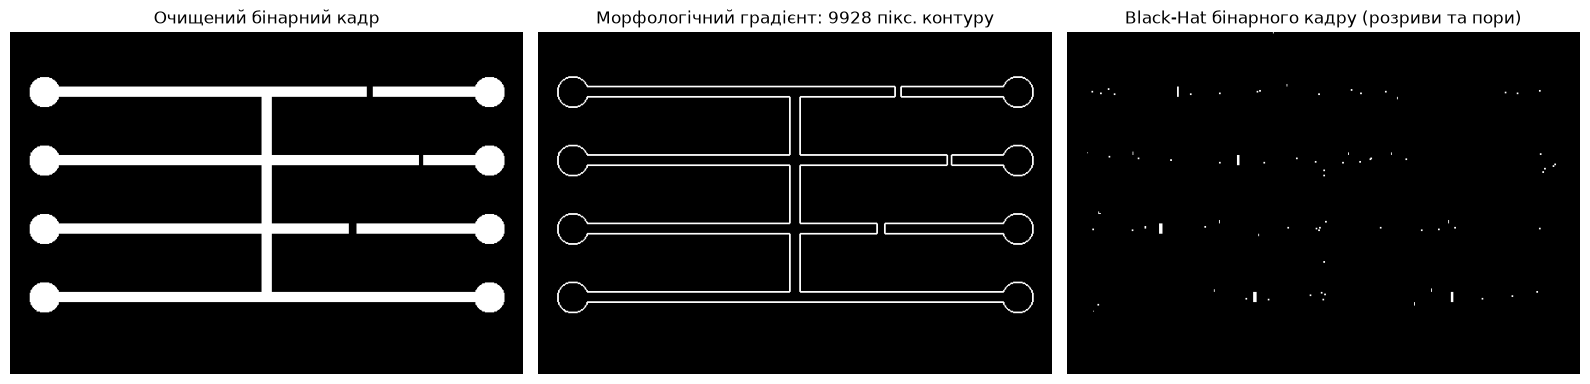

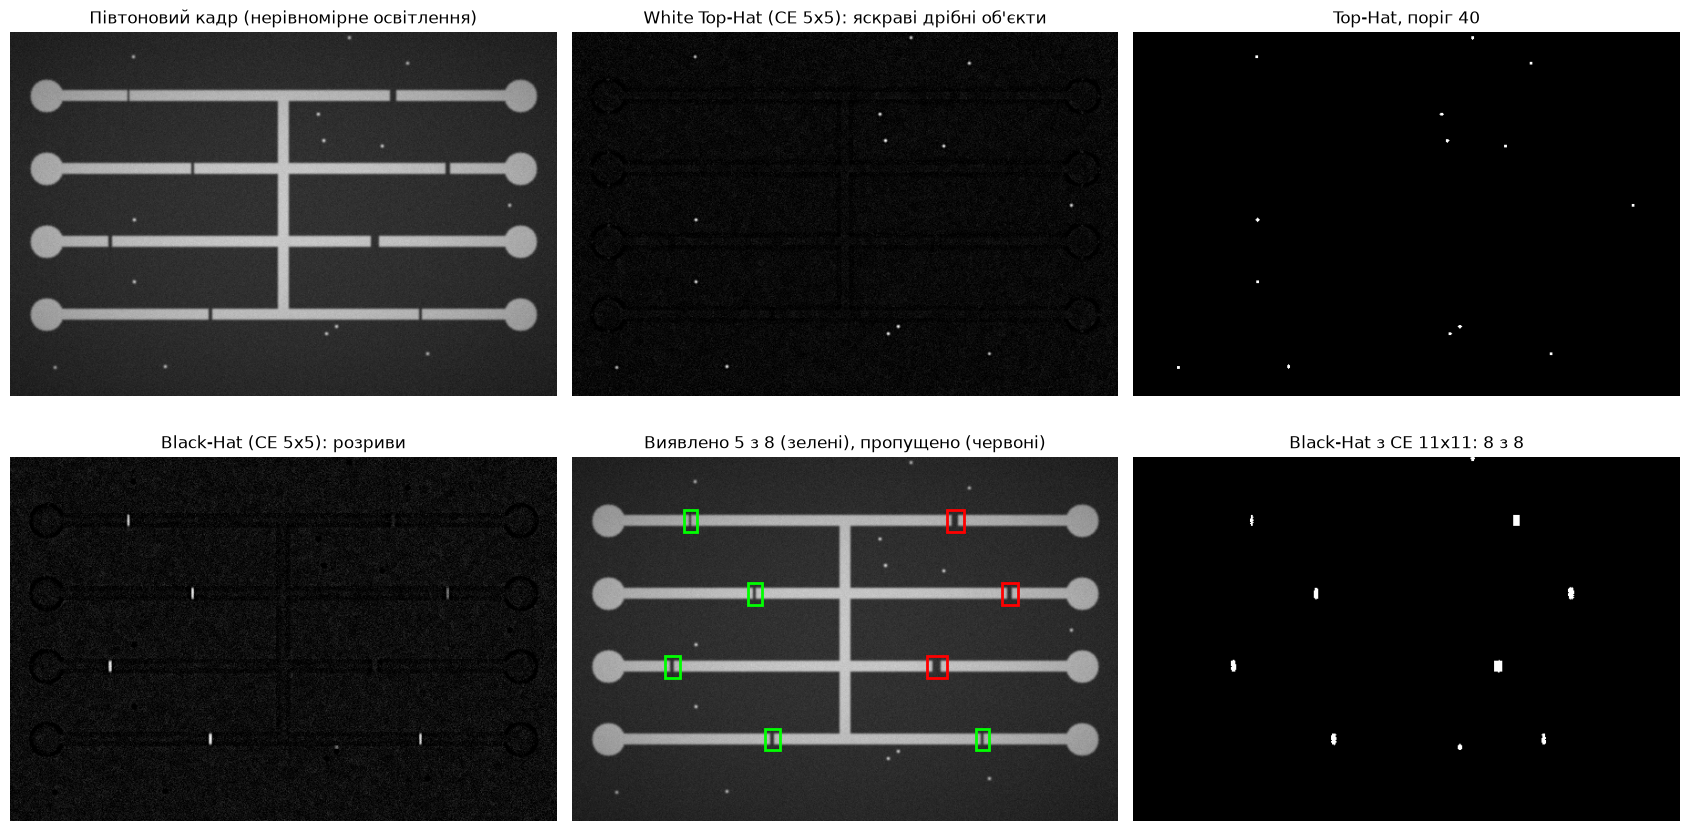


Моделювання завершено. Графіки збережено в 'figures/'.


In [5]:
se_grad = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
morph_gradient = cv2.morphologyEx(img_cleaned, cv2.MORPH_GRADIENT, se_grad)
outer = cv2.subtract(cv2.dilate(img_cleaned, se_grad), img_cleaned)
inner = cv2.subtract(img_cleaned, cv2.erode(img_cleaned, se_grad))
print("\n--- МОРФОЛОГІЧНИЙ ГРАДІЄНТ (еліпс 3x3) ---")
print(f"Пікселів контуру: градієнт {cv2.countNonZero(morph_gradient)}, зовнішній {cv2.countNonZero(outer)}, "
      f"внутрішній {cv2.countNonZero(inner)}")

# конвеєр варіанта 2: закриття, потім Black-Hat = закриття - вихідне зображення
closing_gray = cv2.morphologyEx(img_gray, cv2.MORPH_CLOSE, se_rect, iterations=N_ITER)
blackhat_gray = cv2.subtract(closing_gray, img_gray)
diff_bh = int(np.abs(blackhat_gray.astype(int)
                     - cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, se_rect, iterations=N_ITER).astype(int)).max())
tophat_gray = cv2.morphologyEx(img_gray, cv2.MORPH_TOPHAT, se_rect, iterations=N_ITER)
blackhat_big = cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, np.ones((11, 11), np.uint8))
blackhat_bin = cv2.morphologyEx(img_raw, cv2.MORPH_BLACKHAT, se_rect, iterations=N_ITER)

mask_bh = (blackhat_gray > TH_BLACKHAT).astype(np.uint8) * 255
mask_th = (tophat_gray > TH_TOPHAT).astype(np.uint8) * 255
mask_big = (blackhat_big > TH_BLACKHAT).astype(np.uint8) * 255


def evaluate_breaks(mask, min_area=10):
    """Для кожного відомого розриву перевіряє, чи відгук займає >= 50 % його площі;
    рахує також компоненти відгуку (площею >= min_area), що не збігаються з розривами."""
    found = []
    for bx, by, w in BREAKS:
        x0 = bx - w // 2
        win = mask[by - TW // 2 - 1:by + TW // 2 + 1, x0:x0 + w]
        found.append(np.count_nonzero(win) >= 0.5 * w * TW)
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    zone = np.zeros_like(mask, dtype=bool)
    for bx, by, w in BREAKS:
        zone[by - TW // 2 - 3:by + TW // 2 + 3, bx - w // 2 - 3:bx + w - w // 2 + 3] = True
    false_alarms = sum(1 for i in range(1, n)
                       if st[i, cv2.CC_STAT_AREA] >= min_area and not zone[lab == i].any())
    small = sum(1 for i in range(1, n) if st[i, cv2.CC_STAT_AREA] < min_area)
    return found, false_alarms, small


found_5, fa_5, small_5 = evaluate_breaks(mask_bh)
found_11, fa_11, small_11 = evaluate_breaks(mask_big)
found_bin, fa_bin, small_bin = evaluate_breaks((blackhat_bin > 0).astype(np.uint8) * 255)
n_dust, _, st_dust = count_components(mask_th)
dust_found = int(np.sum(st_dust[1:, cv2.CC_STAT_AREA] >= 4))

print("\n--- КОНВЕЄР ВАРІАНТА 2: CLOSING -> BLACK-HAT (RECT {0}x{0}) ---".format(K_SIZE))
print(f"cv2.MORPH_BLACKHAT збігається з (закриття - вихідне): max різниця {diff_bh} рівнів")
print(f"{'Розрив (x, y)':<16}{'ширина':>8}{'бінарний 5x5':>16}{'півтон. 5x5':>14}{'півтон. 11x11':>16}")
for (bx, by, w), fb, f5, f11 in zip(BREAKS, found_bin, found_5, found_11):
    yn = lambda v: "так" if v else "ні"
    print(f"({bx:3d}, {by:3d})      {w:>8}{yn(fb):>16}{yn(f5):>14}{yn(f11):>16}")
print(f"Виявлено розривів: бінарний кадр {sum(found_bin)} з {len(BREAKS)}, півтоновий (СЕ 5x5) {sum(found_5)} з {len(BREAKS)}, "
      f"півтоновий (СЕ 11x11) {sum(found_11)} з {len(BREAKS)}")
print(f"Хибних компонент (площа >= 10 пікс., поза розривами): бінарний {fa_bin}, півтоновий 5x5 {fa_5}, 11x11 {fa_11}")
print(f"Малих компонент (пори, площа < 10 пікс.) у бінарному відгуку: {small_bin}")
print(f"Top-Hat (СЕ 5x5, поріг {TH_TOPHAT}): виявлено яскравих крапинок пилу {dust_found} (внесено 14)")
print(f"Площа виявлених дефектів Black-Hat (поріг {TH_BLACKHAT}, СЕ 5x5): {cv2.countNonZero(mask_bh)} пікс.")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
axes[0].imshow(img_cleaned, cmap='gray')
axes[0].set_title("Очищений бінарний кадр")
axes[1].imshow(morph_gradient, cmap='gray')
axes[1].set_title(f"Морфологічний градієнт: {cv2.countNonZero(morph_gradient)} пікс. контуру")
axes[2].imshow(blackhat_bin, cmap='gray')
axes[2].set_title("Black-Hat бінарного кадру (розриви та пори)")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/morphological_grad.png", dpi=300)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes[0, 0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Півтоновий кадр (нерівномірне освітлення)")
axes[0, 1].imshow(tophat_gray, cmap='gray')
axes[0, 1].set_title("White Top-Hat (СЕ 5x5): яскраві дрібні об'єкти")
axes[0, 2].imshow(mask_th, cmap='gray')
axes[0, 2].set_title(f"Top-Hat, поріг {TH_TOPHAT}")
axes[1, 0].imshow(blackhat_gray, cmap='gray')
axes[1, 0].set_title("Black-Hat (СЕ 5x5): розриви")
axes[1, 1].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
for (bx, by, w), ok in zip(BREAKS, found_5):
    axes[1, 1].add_patch(Rectangle((bx - w // 2 - 6, by - TW // 2 - 6), w + 12, TW + 12, fill=False,
                                   edgecolor='lime' if ok else 'red', linewidth=2))
axes[1, 1].set_title(f"Виявлено {sum(found_5)} з {len(BREAKS)} (зелені), пропущено (червоні)")
axes[1, 2].imshow(mask_big, cmap='gray')
axes[1, 2].set_title(f"Black-Hat з СЕ 11x11: {sum(found_11)} з {len(BREAKS)}")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/tophat_blackhat_comp.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Градієнт, Top-Hat та Black-Hat.**

Морфологічний градієнт (еліпс $3 \times 3$): 9928 пікселів контуру, з них зовнішній 4972 та внутрішній 4956 ($4972 + 4956 = 9928$, що збігається з формулою теорії). Контур має товщину 1–2 пікселі й не залежить від рівномірного тла.

Конвеєр варіанта 2: `cv2.MORPH_BLACKHAT` збігається з різницею «закриття мінус вихідне» (максимальна різниця 0 рівнів).

| Розрив $(x, y)$ | Ширина | Бінарний $5 \times 5$ | Півтоновий $5 \times 5$ | Півтоновий $11 \times 11$ |
|---|---|---|---|---|
| (130, 70) | 2 | так | так | так |
| (420, 70) | 7 | ні | ні | так |
| (200, 150) | 3 | так | так | так |
| (480, 150) | 5 | ні | ні | так |
| (110, 230) | 4 | так | так | так |
| (400, 230) | 9 | ні | ні | так |
| (220, 310) | 4 | так | так | так |
| (450, 310) | 3 | так | так | так |

Виявлено розривів: бінарний кадр 5 з 8, півтоновий із СЕ $5 \times 5$ — 5 з 8, із СЕ $11 \times 11$ — 8 з 8. Хибних компонент (площа $\ge 10$ пікс. поза розривами): 0, 0 та 2 відповідно. У бінарному відгуку ще є 72 малі компоненти (пори, площа $< 10$ пікс.), які відсікаються фільтром за площею. Top-Hat ($5 \times 5$, поріг 40) знайшов 14 яскравих крапок пилу з 14 внесених. Площа дефектів, виявлених Black-Hat ($5 \times 5$, поріг 40), — 194 пікс.

Збільшення СЕ до $11 \times 11$ знаходить усі вісім розривів (найширший — 9 пікселів), але ціною двох хибних компонент (причину я окремо не досліджував).

## 5. Висновки

1. Ерозія з елементом $5 \times 5$ зменшила площу кадру на 37.0 % (33239 $\to$ 20950 пікс.), діляція збільшила на 42.0 % (до 47192 пікс.). Діляція закриває розриви шириною до 4 пікселів, а ширші (7, 5, 9 пікселів) залишаються відкритими.

2. Відкриття й закриття ідемпотентні, що підтверджено на кадрі. Окремо відкриття збільшило кількість хибних пікселів (523 проти 357), бо розширило пори, а закриття залишило шум на тлі (112 компонент). Послідовність «закриття, потім відкриття» дала найкращий результат: 4 компоненти й 218 хибних пікселів.

3. Морфологічний градієнт дорівнює сумі внутрішнього та зовнішнього контурів ($4972 + 4956 = 9928$ пікс.) і виділяє межі доріжок незалежно від їхньої яскравості.

4. Конвеєр Closing $\to$ Black-Hat із елементом варіанта $5 \times 5$ виявив 5 з 8 розривів: усі розриви до 4 пікселів і жодного ширшого. Це пряме наслідок співвідношення «ширина розриву $<$ розмір СЕ». Елемент $11 \times 11$ виявив усі 8, але додав 2 хибні компоненти.

5. Top-Hat знайшов усі 14 внесених крапок пилу на півтоновому кадрі. Результат залежить від порога й від форми та розміру СЕ, тому для реальної дефектоскопії елемент слід підбирати під найвужчий розрив, який потрібно знаходити. Усі експерименти виконано на синтетичних кадрах.

## Відповідь на контрольні питання

**1. Що таке структуруючий елемент (ядро) у математичній морфології, і як його форма (прямокутник, хрест, еліпс) впливає на результат геометричної обробки?**

* **Визначення:** Структуруючий елемент (ядро або примітив) — це невелика матриця заданої форми та розміру з визначеною опорною точкою (зазвичай у центрі), яка використовується як «зонд» для взаємодії з пікселями зображення під час морфологічних перетворень.
* **Вплив форми ядра:**
* **Прямокутник (квадрат):** Впливає однаково за ортогональними та діагональними напрямками (8-зв'язність), формує чіткі прямі кути, добре зберігає горизонтальні й вертикальні межі, але «оквадрачує» округлі об'єкти.
* **Хрест:** Враховує лише горизонтальний і вертикальний напрямки (4-зв'язність), ігноруючи діагональні сусідні пікселі. Завдяки цьому він краще зберігає гострі кути, тонкі діагональні лінії та менше спотворює дрібні деталі порівняно з прямокутником такого ж габариту.
* **Еліпс (диск/коло):** Забезпечує ізотропну (рівномірну в усіх напрямках) обробку, м'яко згладжує контури та зберігає природну округлу геометрію об'єктів без створення штучних кутових артефактів.



---

**2. У чому полягає математична та геометрична відмінність між операціями ерозії ($A \ominus B$) та діляції ($A \oplus B$) над бінарними множинами?**

* **Ерозія ($A \ominus B$):**
* *Математично:* Множина всіх точок $z$, для яких структуруючий елемент $B$, зсунутий у точку $z$, повністю міститься всередині множини об'єкта $A$:

$$A \ominus B = \{ z \mid (B)_z \subseteq A \}$$


* *Геометрично:* Звужує (витончує) світлі об'єкти, зрізаючи зовнішній шар пікселів по контуру, видаляє дрібні шумові викиди та розриває тонкі перемички, менші за розмір ядра $B$.


* **Діляція ($A \oplus B$):**
* *Математично:* Множина всіх точок $z$, для яких відображений відносно початку координат елемент $\hat{B}$, зсунутий у точку $z$, має непорожній перетин із множиною $A$:

$$A \oplus B = \{ z \mid (\hat{B})_z \cap A \neq \emptyset \}$$


* *Геометрично:* Розширює (потовщує) світлі об'єкти, нарощуючи їхній зовнішній контур, заповнює дрібні отвори й тріщини всередині фігур та об'єднує близько розташовані фрагменти.



---

**3. Чому операції морфологічного відкриття та закриття називають ідемпотентними, і в яких випадках їх застосовують замість окремих ерозій та діляцій?**

* **Ідемпотентність:** Операції відкриття ($A \circ B$) та закриття ($A \bullet B$) є ідемпотентними, оскільки їх повторне застосування тим самим структуруючим елементом не змінює вже отриманий результат:

$$(A \circ B) \circ B = A \circ B, \qquad (A \bullet B) \bullet B = A \bullet B$$



Після першого проходу всі деталі, менші за ядро $B$, уже усунуті або заповнені, а контури узгоджені з формою $B$, тому подальші застосування не дають нового ефекту.
* **Випадки застосування замість окремих ерозій та діляцій:** Окремі ерозія або діляція незворотно зменшують або збільшують площу та лінійні розміри об'єктів. Відкриття ($A \circ B = (A \ominus B) \oplus B$) і закриття ($A \bullet B = (A \oplus B) \ominus B$) застосовують тоді, коли потрібно **очистити зображення від дефектів без суттєвої зміни загального масштабу та розмірів основних об'єктів**:
* *Відкриття* — для видалення дрібного світлого шуму («сіль»), тонких виступів і розділення злиплих об'єктів зі збереженням їхніх початкових розмірів.
* *Закриття* — для заповнення дрібних темних отворів («перець»), вузьких тріщин і розривів контуру без роздування зовнішніх меж фігур.



---

**4. Яким чином морфологічне відкриття дозволяє розділити два частково перекриті круглі об'єкти, з'єднані тонким перешийком?**

Морфологічне відкриття послідовно виконує ерозію та діляцію одним і тим самим структуруючим елементом $B$: $A \circ B = (A \ominus B) \oplus B$. Якщо обрати ядро (наприклад, диск), діаметр якого **більший за товщину перешийка, але менший за діаметр основних круглих об'єктів**, процес відбувається у два етапи:

1. **Ерозія ($A \ominus B$):** Структуруючий елемент не поміщається в межах вузького перешийка, тому пікселі перемички повністю стираються — зв'язок між фігурами розривається. Основні круглі об'єкти при цьому лише зменшуються в радіусі на величину радіуса ядра, але зберігаються.
2. **Діляція ($\oplus B$):** Зменшені ядра круглих об'єктів відновлюються до своїх вихідних розмірів, тоді як розірваний перешийок уже не відновлюється, оскільки між об'єктами утворився розрив, більший за розмір елемента $B$.

---

**5. Як формується морфологічний градієнт, і чим внутрішній та зовнішній градієнти відрізняються від повного градієнта $G(A) = (A \oplus B) - (A \ominus B)$?**

* **Формування повного (симетричного) градієнта:** Обчислюється як попіксельна різниця між результатом діляції та результатом ерозії: $G(A) = (A \oplus B) - (A \ominus B)$. Він виділяє контурну смугу, розташовану симетрично по обидва боки від початкової межі об'єкта.
* **Відмінності внутрішнього та зовнішнього градієнтів:**
* **Внутрішній градієнт** $G_{\text{int}}(A) = A - (A \ominus B)$ — різниця між вихідним зображенням і результатом ерозії. Виділяє контур, який лежить **суворо всередині** самого об'єкта (належить пікселям переднього плану) і має вдвічі меншу товщину порівняно з повним градієнтом.
* **Зовнішній градієнт** $G_{\text{ext}}(A) = (A \oplus B) - A$ — різниця між результатом діляції та вихідним зображенням. Виділяє контур, який лежить **суворо зовні** об'єкта (належить пікселям фону, безпосередньо прилягаючи до його межі), і також є тоншим за повний градієнт.



---

**6. Опишіть принцип функціонування перетворення «білий капелюх» (White Top-Hat). Чому воно ефективно усуває повільні градієнтні перепади фонової яскравості?**

* **Принцип функціонування:** Перетворення White Top-Hat визначається як різниця між вихідним напівтоновим зображенням $f$ та результатом його морфологічного відкриття:

$$T_{\text{hat}}(f) = f - (f \circ B)$$



Операція відкриття $f \circ B$ зрізає всі локальні світлі піки та дрібні світлі об'єкти, менші за розмір ядра $B$, формуючи оцінку плавного фону. Подальше віднімання відкритого зображення від оригіналу залишає лише ці виділені дрібні світлі деталі.
* **Причина усунення повільних градієнтів фону:** Плавні перепади фонової яскравості (нерівномірне освітлення) мають значно більший просторовий масштаб, ніж розмір структуруючого елемента $B$. Через це відкриття $f \circ B$ практично не змінює повільний градінт фону, і він однаково присутній як у $f$, так і в $(f \circ B)$. Під час віднімання $f - (f \circ B)$ фонова складова взаємно скорочується, вирівнюючи яскравість фону.

---

**7. У чому полягає сутність перетворення «чорний капелюх» (Black-Hat), і чому розмір структуруючого елемента $B$ при цьому повинен перевищувати геометричну товщину темних тріщин?**

* **Сутність перетворення:** Перетворення Black-Hat визначається як різниця між результатом морфологічного закриття зображення $f \bullet B$ та вихідним зображенням $f$:

$$B_{\text{hat}}(f) = (f \bullet B) - f$$



Закриття заповнює локальні темні провали (тріщини, пори, тонкі темні лінії) яскравістю навколишнього світлого фону, а віднімання оригіналу $f$ перетворює ці темні дефекти на яскраві світлі об'єкти на темному вирівняному фоні.
* **Необхідність перевищення товщини тріщин розміром ядра $B$:** На першому кроці закриття виконується діляція $f \oplus B$, яка нарощує світлі краї навколо темної тріщини назустріч один одному. Щоб протилежні світлі стінки тріщини зімкнулися і повністю заповнили її просвіт фоновим значенням, розмір структуруючого елемента $B$ має бути більшим за геометричну ширину тріщини. Якщо $B$ буде меншим або рівним товщині тріщини, ядро вільно поміститься всередині неї, закриття не заповнить дефект, і різниця $(f \bullet B) - f$ не виділить тріщину.